# 02 – Persistenz, Dwell Times und Rückkehrdynamik

Dieses Notebook verwendet die Ausgaben von Notebook 01. Der Persistenzfilter
ersetzen kurze Runs (Standard: weniger als 5 Frames), ohne die Rohsequenz zu
verändern. Rückkehrstatistiken verwenden nur Abgänge mit vollständigem
Beobachtungshorizont; abgeschnittene Endfenster gelten nicht als Nicht-Rückkehr.

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.pipeline import export_team3, select_filter_demo
from src.plots import save_fig, setup_style
from src.sequences import (
    dwell_runs, normalize_transition_counts, return_summary, transition_counts,
)

setup_style()
OUT = PROJECT / 'data' / 'processed'
STATE_ORDER = [
    'monomer_gas', 'dimer_dominated', 'trimer_like', 'tetra_like',
    'loose_four_cluster', 'large_cluster', 'mixed_transition',
]
sequences = pd.read_csv(OUT / 'macrostate_sequences.csv')
assert 'n_particles' in sequences


## Dwell-Time-Tabellen

Jede zusammenhängende Verweildauer wird separat gespeichert. Erste und letzte
Runs sind als links-/rechtszensiert markiert. Sekundenwerte verwenden die
mediane Sampling-Schrittweite des jeweiligen Laufs.

In [2]:
dwell_tables = []
for (run_id, graph_type), frame in sequences.groupby(['run_id', 'graph_type'], sort=True):
    frame = frame.sort_values('time')
    metadata = frame.iloc[0]
    for sequence_type, column in [('raw', 'macrostate_raw'), ('filtered', 'macrostate_filtered')]:
        runs = dwell_runs(frame[column].tolist(), frame.time.to_numpy())
        runs['run_id'] = run_id
        runs['seed'] = metadata.seed
        runs['model_type'] = metadata.model_type
        runs['material_type'] = metadata.material_type
        runs['n_particles'] = int(metadata.n_particles)
        runs['graph_type'] = graph_type
        runs['sequence_type'] = sequence_type
        dwell_tables.append(runs)
dwell = pd.concat(dwell_tables, ignore_index=True)
dwell.to_csv(OUT / 'dwell_times.csv', index=False)
print(f'Dwell-Time-Zeilen: {len(dwell)}')
display(dwell.head())

Dwell-Time-Zeilen: 393


,state,start_index,end_index,start_time,end_time,dwell_steps,dwell_seconds,left_censored,right_censored,run_id,seed,model_type,material_type,n_particles,graph_type,sequence_type
0,monomer_gas,0,22,0.000005,0.000115,23,0.000115,True,False,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw
1,dimer_dominated,23,32,0.000120,0.000165,10,0.000050,False,False,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw
2,trimer_like,33,43,0.000170,0.000220,11,0.000055,False,False,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw
3,loose_four_cluster,44,45,0.000225,0.000230,2,0.000010,False,False,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw
4,tetra_like,46,999,0.000235,0.005000,954,0.004770,False,True,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw


## Übergänge, Selbstübergänge und Returns

Übergangswahrscheinlichkeiten werden aus gepoolten Zählungen innerhalb einer
Gruppe berechnet, nicht als ungewichteter Mittelwert kurzer und langer Läufe.
Return Probability verwendet T=50 Frames; Mean Return Time T=200 Frames.

In [3]:
metric_rows = []
transition_frames = []
for (run_id, graph_type), frame in sequences.groupby(['run_id', 'graph_type'], sort=True):
    frame = frame.sort_values('time')
    metadata = frame.iloc[0]
    for sequence_type, column in [('raw', 'macrostate_raw'), ('filtered', 'macrostate_filtered')]:
        sequence = frame[column].tolist()
        times = frame.time.to_numpy()
        probabilities = normalize_transition_counts(transition_counts(sequence, STATE_ORDER))
        for state in sorted(set(sequence)):
            state_dwell = dwell[
                (dwell.run_id == run_id) & (dwell.graph_type == graph_type)
                & (dwell.sequence_type == sequence_type) & (dwell.state == state)
            ]
            r50 = return_summary(sequence, times, state, horizon=50)
            r200 = return_summary(sequence, times, state, horizon=200)
            metric_rows.append({
                'run_id': run_id, 'seed': metadata.seed,
                'model_type': metadata.model_type,
                'material_type': metadata.material_type,
                'n_particles': int(metadata.n_particles), 'graph_type': graph_type,
                'sequence_type': sequence_type, 'state': state,
                'n_frames': len(sequence), 'frequency': sequence.count(state) / len(sequence),
                'mean_dwell_steps': state_dwell.dwell_steps.mean(),
                'mean_dwell_seconds': state_dwell.dwell_seconds.mean(),
                'self_transition_probability': probabilities.loc[state, state],
                'return_probability_T50': r50['return_probability'],
                'return_eligible_T50': r50['eligible_departures'],
                'returns_T50': r50['returns'],
                'mean_return_steps_T200': r200['mean_return_steps'],
                'mean_return_seconds_T200': r200['mean_return_seconds'],
                'return_eligible_T200': r200['eligible_departures'],
                'returns_T200': r200['returns'],
            })

grouped = sequences.groupby(
    ['n_particles', 'model_type', 'material_type', 'graph_type'], sort=True
)
for (n_particles, model, material, graph_type), group in grouped:
    for sequence_type, column in [('raw', 'macrostate_raw'), ('filtered', 'macrostate_filtered')]:
        counts = pd.DataFrame(0.0, index=STATE_ORDER, columns=STATE_ORDER)
        for _, run in group.groupby('run_id'):
            run = run.sort_values('time')
            counts += transition_counts(run[column].tolist(), STATE_ORDER)
        probabilities = normalize_transition_counts(counts)
        for source in STATE_ORDER:
            for target in STATE_ORDER:
                transition_frames.append({
                    'n_particles': n_particles, 'model_type': model,
                    'material_type': material, 'graph_type': graph_type,
                    'sequence_type': sequence_type, 'source': source, 'target': target,
                    'count': counts.loc[source, target],
                    'probability': probabilities.loc[source, target],
                })

sequence_metrics = pd.DataFrame(metric_rows)
transitions = pd.DataFrame(transition_frames)
sequence_metrics.to_csv(OUT / 'sequence_metrics.csv', index=False)
transitions.to_csv(OUT / 'transition_matrices.csv', index=False)
export_team3(sequences, OUT / 'team3_macrostates.csv')
display(sequence_metrics.head())
print('Team-3-Export:', len(sequences[sequences.graph_type == 'meso']), 'Zeilen')

,run_id,seed,model_type,material_type,n_particles,graph_type,sequence_type,state,n_frames,frequency,mean_dwell_steps,mean_dwell_seconds,self_transition_probability,return_probability_T50,return_eligible_T50,returns_T50,mean_return_steps_T200,mean_return_seconds_T200,return_eligible_T200,returns_T200
0,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw,dimer_dominated,1000,0.010,10.0,0.000050,0.900000,0.0,1,0,NaN,NaN,1,0
1,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw,loose_four_cluster,1000,0.002,2.0,0.000010,0.500000,0.0,1,0,NaN,NaN,1,0
2,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw,monomer_gas,1000,0.023,23.0,0.000115,0.956522,0.0,1,0,NaN,NaN,1,0
3,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw,tetra_like,1000,0.954,954.0,0.004770,1.000000,NaN,0,0,NaN,NaN,0,0
4,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,raw,trimer_like,1000,0.011,11.0,0.000055,0.909091,0.0,1,0,NaN,NaN,1,0


Team-3-Export: 19000 Zeilen


## Abbildung 1 – Roh- versus gefilterte Zustandssequenz

Der Repräsentativfall wird deterministisch aus der **größten Anzahl Frames mit
`macrostate_raw != macrostate_filtered`** gewählt; Gleichstände entscheiden zuerst
Graph, dann Run-ID. Im finalen Export ist dieser Effekt selten: er kommt nur im Hard-
und Near-Graphen vor, während im Meso-Graphen unter `min_dwell=5` keine Frame
gefiltert wird. Deshalb zeigt die Abbildung den realen Grenzfall, kein typisches Meso-Ergebnis.


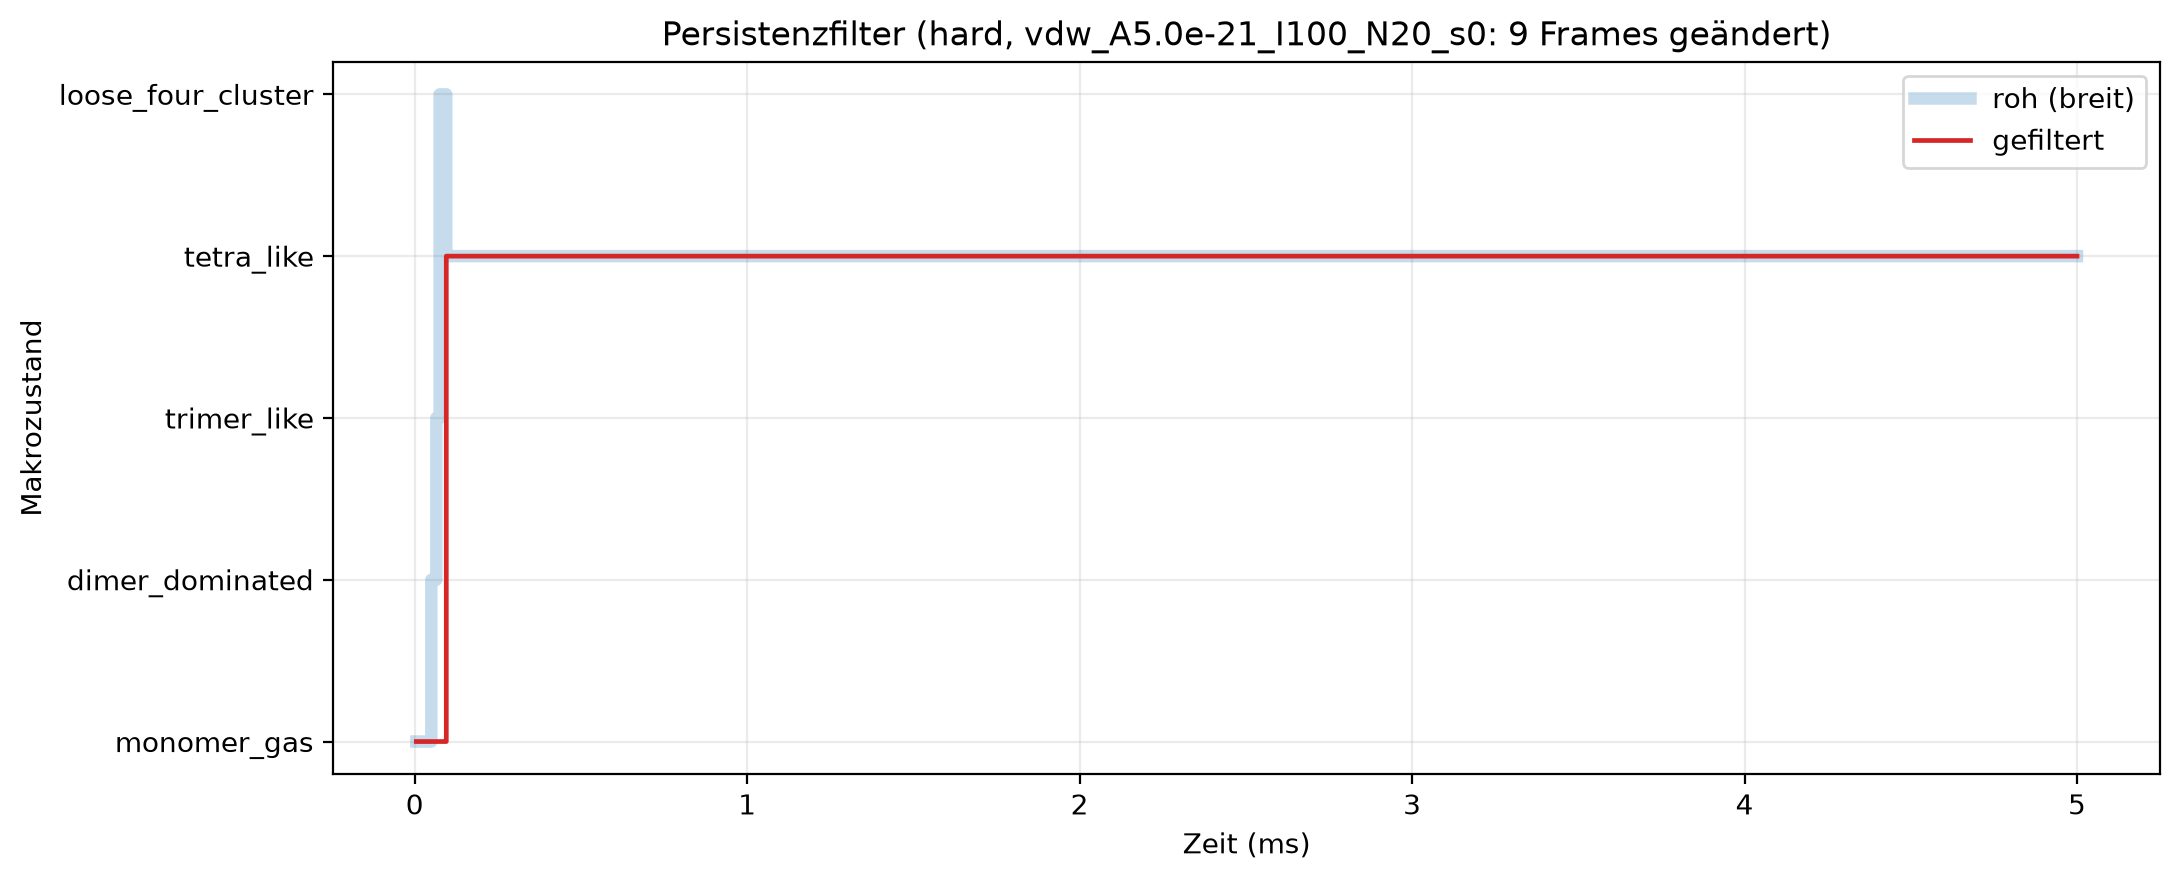

Frames mit Roh-≠Filtered im gesamten Export: 57
Repräsentativfall: hard vdw_A5.0e-21_I100_N20_s0 9
Meso-Filtered-Änderungen: 0


In [4]:
meso20 = sequences[(sequences.n_particles == 20) & (sequences.graph_type == 'meso')]
filter_changes = (sequences.macrostate_raw != sequences.macrostate_filtered).sum()
selection = select_filter_demo(sequences)
graph_type = selection['graph_type']
run_id = selection['run_id']
selected_graph = sequences[sequences.graph_type == graph_type]
selected = selected_graph[selected_graph.run_id == run_id].sort_values('time')
active_states = [s for s in STATE_ORDER
                 if s in set(selected.macrostate_raw) | set(selected.macrostate_filtered)]
state_y = {state: index for index, state in enumerate(active_states)}

fig, ax = plt.subplots(figsize=(11, 4.5))
x_ms = selected.time * 1e3
ax.step(
    x_ms, selected.macrostate_raw.map(state_y), where='post',
    linewidth=4.5, alpha=0.25, color='tab:blue', label='roh (breit)',
)
ax.step(
    x_ms, selected.macrostate_filtered.map(state_y), where='post',
    linewidth=1.7, color='tab:red', label='gefiltert',
)
ax.set_yticks(range(len(active_states)), active_states)
ax.set_xlabel('Zeit (ms)')
ax.set_ylabel('Makrozustand')
ax.set_title(f'Persistenzfilter ({graph_type}, {run_id}: {selection["changed"]} Frames geändert)')
ax.legend()
fig.tight_layout()
save_fig(fig, '01_roh_vs_gefiltert')
plt.show()
print('Frames mit Roh-≠Filtered im gesamten Export:', int(filter_changes))
print('Repräsentativfall:', graph_type, run_id, int(selection['changed']))
print('Meso-Filtered-Änderungen:', int((meso20.macrostate_raw != meso20.macrostate_filtered).sum()))


## Abbildung 3 – Dwell-Time-Verteilungen

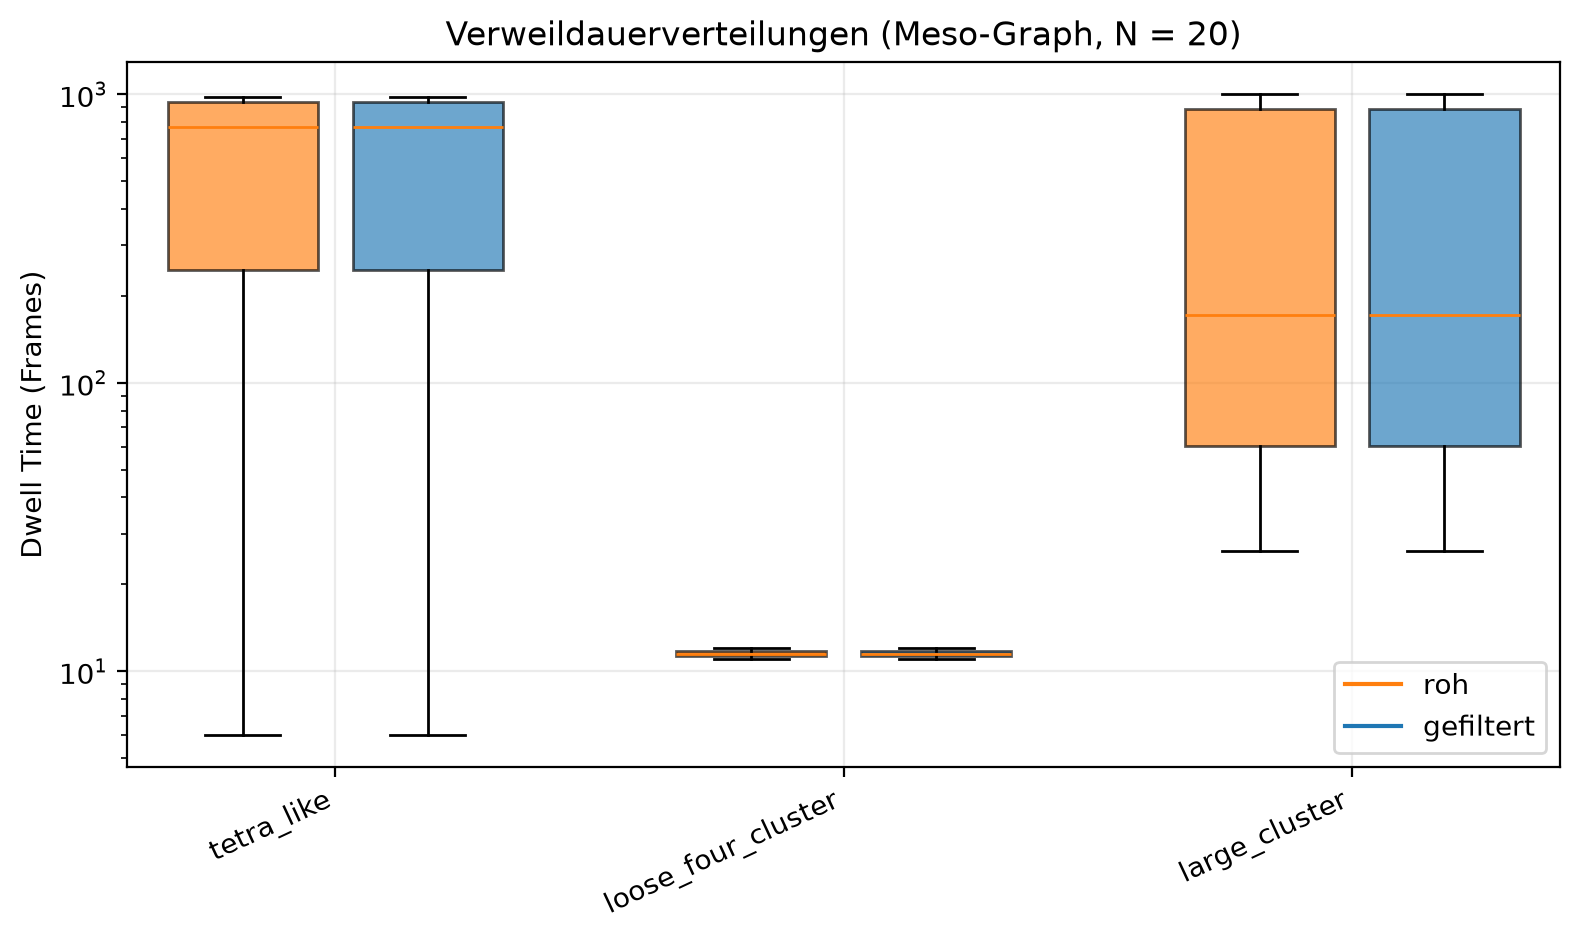

In [5]:
plot_dwell = dwell[(dwell.n_particles == 20) & (dwell.graph_type == 'meso')]
states = [s for s in STATE_ORDER if s in set(plot_dwell.state)]
fig, ax = plt.subplots(figsize=(max(8, 1.7 * len(states)), 4.8))
positions_raw = np.arange(len(states)) * 2.2
raw_data = [plot_dwell[(plot_dwell.state == s) & (plot_dwell.sequence_type == 'raw')].dwell_steps for s in states]
filtered_data = [plot_dwell[(plot_dwell.state == s) & (plot_dwell.sequence_type == 'filtered')].dwell_steps for s in states]
raw_boxes = ax.boxplot(raw_data, positions=positions_raw - 0.4, widths=0.65, patch_artist=True, showfliers=False)
filtered_boxes = ax.boxplot(filtered_data, positions=positions_raw + 0.4, widths=0.65, patch_artist=True, showfliers=False)
for box in raw_boxes['boxes']:
    box.set(facecolor='tab:orange', alpha=0.65)
for box in filtered_boxes['boxes']:
    box.set(facecolor='tab:blue', alpha=0.65)
ax.plot([], [], color='tab:orange', label='roh')
ax.plot([], [], color='tab:blue', label='gefiltert')
ax.set_xticks(positions_raw, states, rotation=25, ha='right')
ax.set_ylabel('Dwell Time (Frames)')
ax.set_yscale('log')
ax.set_title('Verweildauerverteilungen (Meso-Graph, N = 20)')
ax.legend()
fig.tight_layout()
save_fig(fig, '03_dwell_times')
plt.show()

## Abbildung 4 – Transition-Matrix-Heatmaps

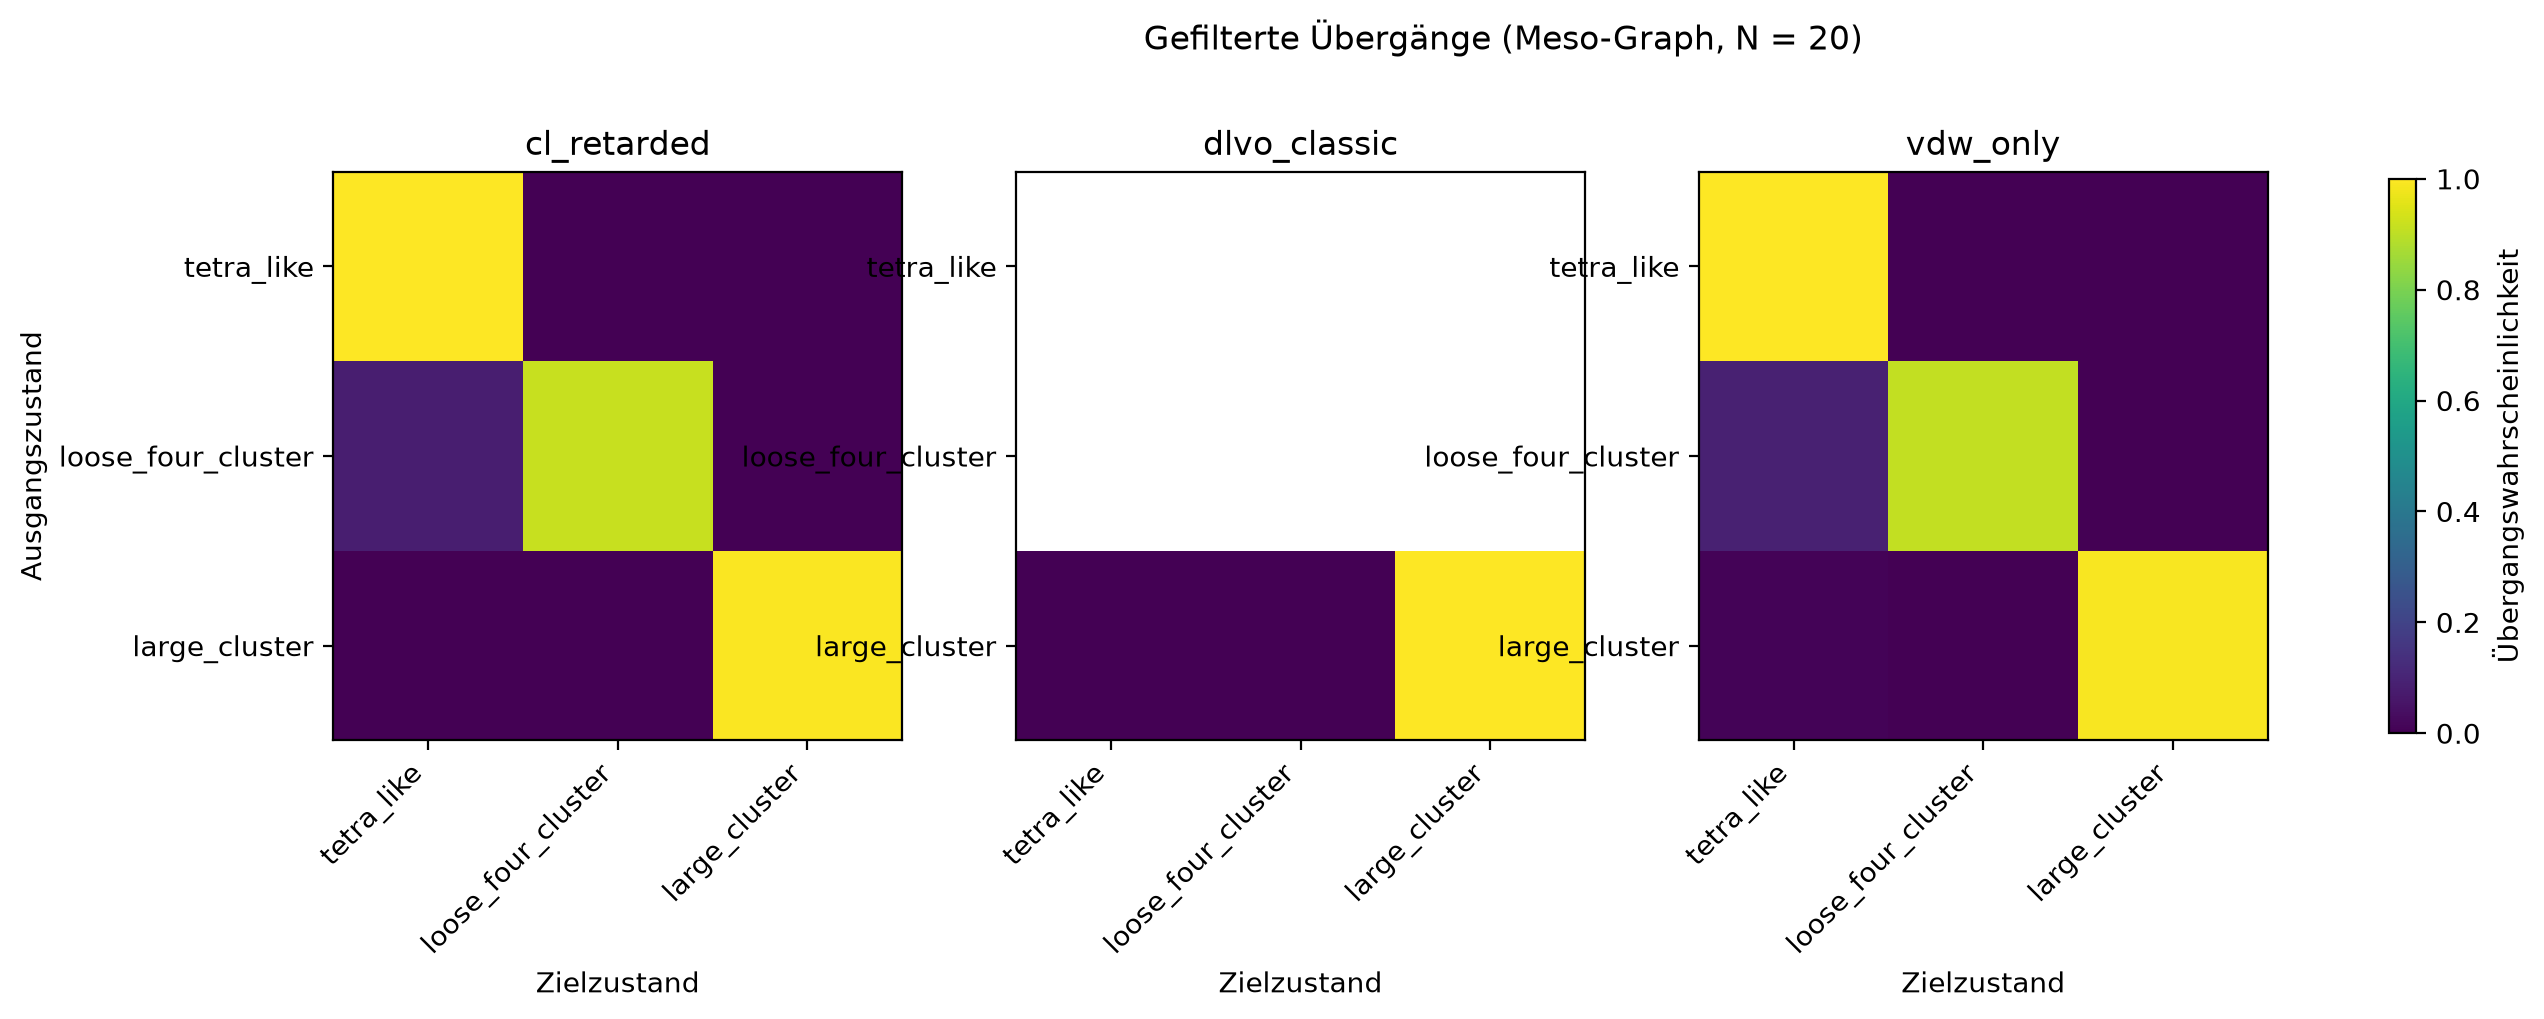

In [6]:
matrix_data = transitions[
    (transitions.n_particles == 20) & (transitions.graph_type == 'meso')
    & (transitions.sequence_type == 'filtered')
]
active_states = [s for s in STATE_ORDER if s in set(meso20.macrostate_filtered)]
models = sorted(meso20.model_type.unique())
fig, axes = plt.subplots(1, len(models), figsize=(5.2 * len(models), 4.5), squeeze=False)
image = None
for ax, model in zip(axes[0], models):
    subset = matrix_data[matrix_data.model_type == model]
    counts = subset.groupby(['source', 'target'])['count'].sum().unstack(fill_value=0)
    counts = counts.reindex(index=active_states, columns=active_states, fill_value=0.0)
    probabilities = normalize_transition_counts(counts)
    image = ax.imshow(probabilities, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(len(active_states)), active_states, rotation=45, ha='right')
    ax.set_yticks(range(len(active_states)), active_states)
    ax.set_title(model)
    ax.set_xlabel('Zielzustand')
    ax.grid(False)
axes[0][0].set_ylabel('Ausgangszustand')
if image is not None:
    fig.colorbar(image, ax=axes[0].tolist(), shrink=0.8, label='Übergangswahrscheinlichkeit')
fig.suptitle('Gefilterte Übergänge (Meso-Graph, N = 20)')
save_fig(fig, '04_transition_matrizen')
plt.show()

## Abbildung 5 – Return Probability pro Zustand

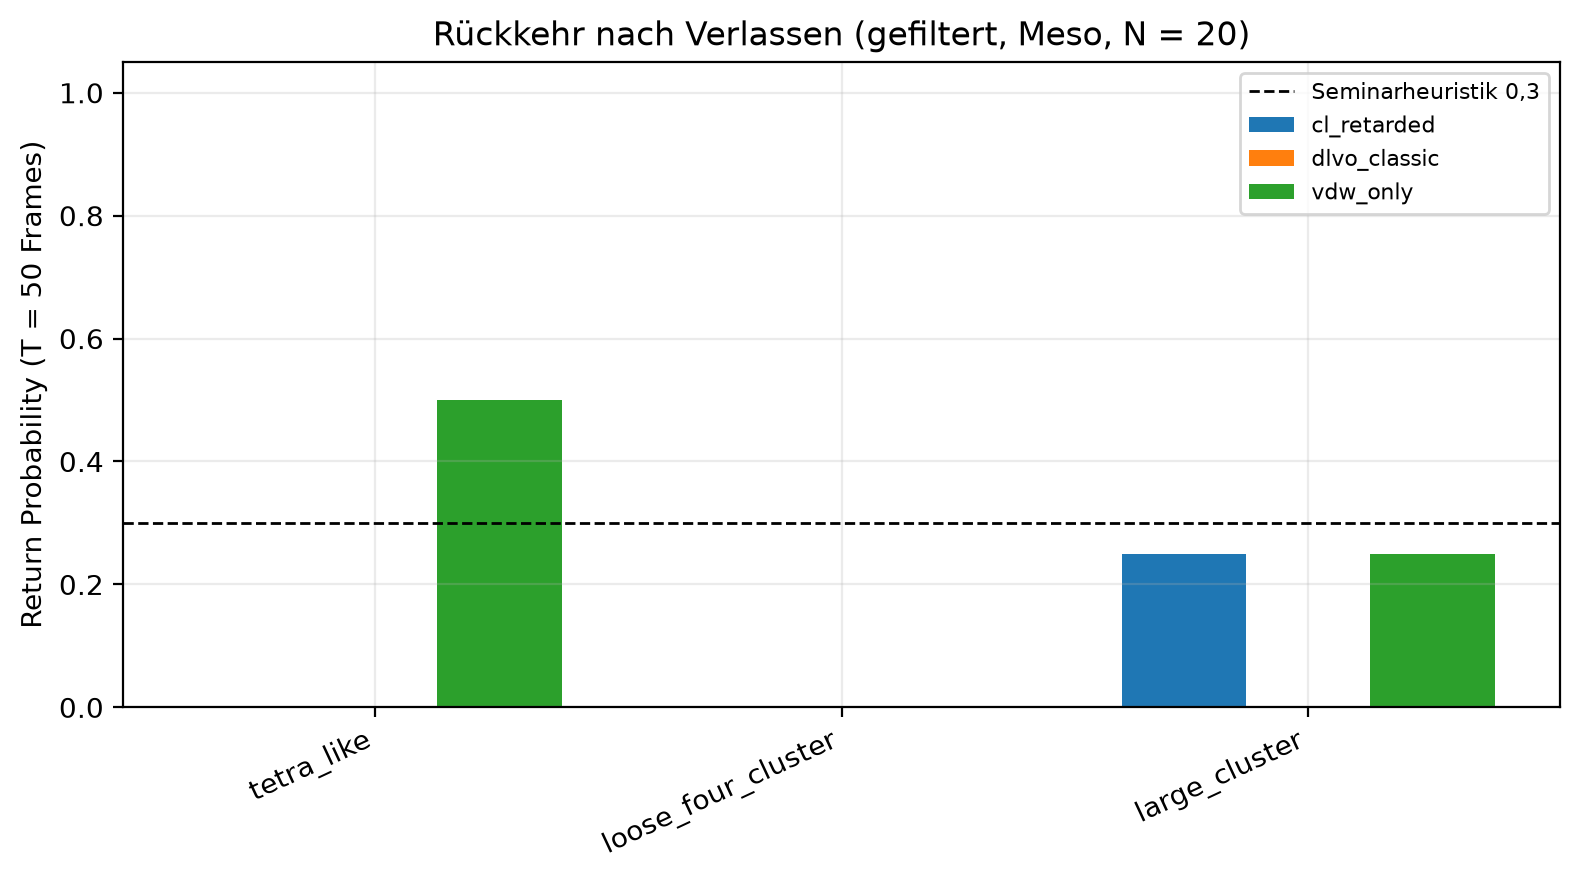

,model_type,state,eligible,returns,return_probability
0,cl_retarded,large_cluster,8,2,0.25
1,cl_retarded,loose_four_cluster,1,0,0.00
2,cl_retarded,tetra_like,2,0,0.00
3,dlvo_classic,large_cluster,0,0,NaN
4,vdw_only,large_cluster,8,2,0.25
5,vdw_only,loose_four_cluster,1,0,0.00
6,vdw_only,tetra_like,2,1,0.50


Anzahl Seeds
model_type   material_type              
cl_retarded  PMBC                      3
             fatty_acid                3
dlvo_classic PMBC                      3
             fatty_acid                3
vdw_only     PMBC                      3
             fatty_acid                3

In [7]:
returns = sequence_metrics[
    (sequence_metrics.n_particles == 20) & (sequence_metrics.graph_type == 'meso')
    & (sequence_metrics.sequence_type == 'filtered')
]
pooled = returns.groupby(['model_type', 'state']).agg(
    eligible=('return_eligible_T50', 'sum'), returns=('returns_T50', 'sum')
).reset_index()
pooled['return_probability'] = pooled.returns / pooled.eligible.replace(0, np.nan)
states = [s for s in STATE_ORDER if s in set(pooled.state)]
models = sorted(pooled.model_type.unique())
x = np.arange(len(states))
width = 0.8 / max(len(models), 1)
fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(states)), 4.5))
for index, model in enumerate(models):
    values = pooled[pooled.model_type == model].set_index('state').return_probability
    heights = [values.get(state, np.nan) for state in states]
    ax.bar(x + index * width, heights, width, label=model)
ax.axhline(0.3, color='black', linestyle='--', linewidth=1, label='Seminarheuristik 0,3')
ax.set_xticks(x + 0.4 - width / 2, states, rotation=25, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Return Probability (T = 50 Frames)')
ax.set_title('Rückkehr nach Verlassen (gefiltert, Meso, N = 20)')
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, '05_return_probability')
plt.show()
display(pooled)

seeds = meso20.groupby(['model_type', 'material_type']).seed.nunique()
display(seeds.rename('Anzahl Seeds').to_frame())
if (seeds < 3).any():
    print('Seed-Reproduzierbarkeit: nicht bestimmbar (weniger als drei Seeds).')

### Interpretation

Eine lange Dwell Time allein ist kein Attraktorbeweis. Return Probability und
Mean Return Time messen verschiedene Aspekte der Rückkehrdynamik. Die Filterung
kann benachbarte Zustände verlängern; deshalb bleiben Rohmetriken als
Sensitivitätsvergleich erhalten. Ergebnisse aus weniger als drei Seeds werden
nicht als reproduzierbar eingestuft.